# EDA with Red Wine Data

## Project question
What physicochemical properties are associated with higher red wine quality?

## About the data
This dataset contains physicochemical test results for red variants of the Portuguese
"Vinho Verde" wine, along with a quality score (0 to 10) given by wine tasters.
There is no data on grape type, brand, or price.

**Source:** UCI Machine Learning Repository, Cortez et al. (2009)

## Columns
**Inputs (physicochemical tests):** fixed acidity, volatile acidity, citric acid,
residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH,
sulphates, alcohol

**Output (sensory data):** quality (score between 0 and 10)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url, sep=";")
print(df.shape)

(1599, 12)


In [2]:
df1 = df.copy()

In [3]:
## Summary of the dataset
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [4]:
## descriptive summary of the dataset
df1.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [5]:
df1.shape

(1599, 12)

In [6]:
## List down all the columns names
df1.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

In [7]:
df1['quality'].unique()

array([5, 6, 7, 4, 8, 3], dtype=int64)

In [8]:
## Missing values in the dataset

df1.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [9]:
## Duplicate records
df1[df1.duplicated()]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
11,7.5,0.500,0.36,6.10,0.071,17.0,102.0,0.99780,3.35,0.80,10.5,5
27,7.9,0.430,0.21,1.60,0.106,10.0,37.0,0.99660,3.17,0.91,9.5,5
40,7.3,0.450,0.36,5.90,0.074,12.0,87.0,0.99780,3.33,0.83,10.5,5
65,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.99620,3.41,0.39,10.9,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1563,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5
1564,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5
1567,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5
1581,6.2,0.560,0.09,1.70,0.053,24.0,32.0,0.99402,3.54,0.60,11.3,5


In [10]:
## Remove the duplicates
print("Rows before:", df1.shape)
print("Duplicate rows:", df1.duplicated().sum())

df1 = df1.drop_duplicates().reset_index(drop=True)
print("Rows after:", df1.shape)

Rows before: (1599, 12)
Duplicate rows: 240
Rows after: (1359, 12)


In [11]:
## Correlation
df1.corr()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.255124,0.667437,0.111025,0.085886,-0.140580,-0.103777,0.670195,-0.686685,0.190269,-0.061596,0.119024
volatile acidity,-0.255124,1.000000,-0.551248,-0.002449,0.055154,-0.020945,0.071701,0.023943,0.247111,-0.256948,-0.197812,-0.395214
citric acid,0.667437,-0.551248,1.000000,0.143892,0.210195,-0.048004,0.047358,0.357962,-0.550310,0.326062,0.105108,0.228057
residual sugar,0.111025,-0.002449,0.143892,1.000000,0.026656,0.160527,0.201038,0.324522,-0.083143,-0.011837,0.063281,0.013640
chlorides,0.085886,0.055154,0.210195,0.026656,1.000000,0.000749,0.045773,0.193592,-0.270893,0.394557,-0.223824,-0.130988
free sulfur dioxide,-0.140580,-0.020945,-0.048004,0.160527,0.000749,1.000000,0.667246,-0.018071,0.056631,0.054126,-0.080125,-0.050463
total sulfur dioxide,-0.103777,0.071701,0.047358,0.201038,0.045773,0.667246,1.000000,0.078141,-0.079257,0.035291,-0.217829,-0.177855
density,0.670195,0.023943,0.357962,0.324522,0.193592,-0.018071,0.078141,1.000000,-0.355617,0.146036,-0.504995,-0.184252
pH,-0.686685,0.247111,-0.550310,-0.083143,-0.270893,0.056631,-0.079257,-0.355617,1.000000,-0.214134,0.213418,-0.055245
sulphates,0.190269,-0.256948,0.326062,-0.011837,0.394557,0.054126,0.035291,0.146036,-0.214134,1.000000,0.091621,0.248835


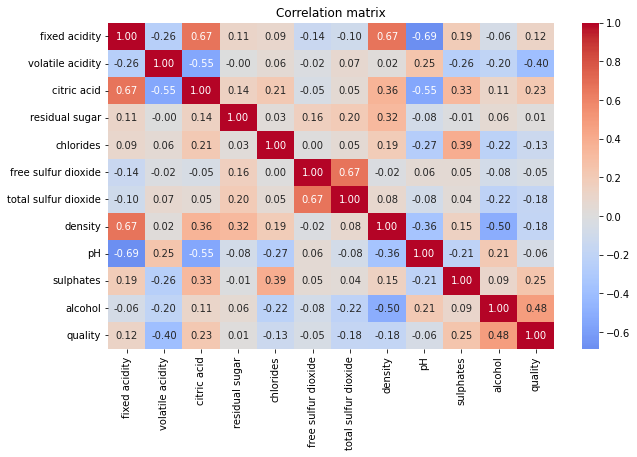

In [12]:
plt.figure(figsize=(10,6))
sns.heatmap(df1.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

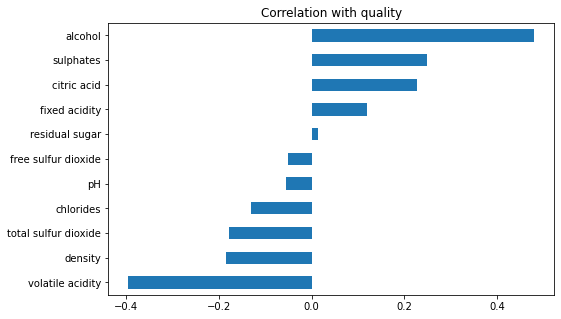

volatile acidity       -0.395214
density                -0.184252
total sulfur dioxide   -0.177855
chlorides              -0.130988
pH                     -0.055245
free sulfur dioxide    -0.050463
residual sugar          0.013640
fixed acidity           0.119024
citric acid             0.228057
sulphates               0.248835
alcohol                 0.480343
Name: quality, dtype: float64


In [13]:
# Correlation quality
corr_quality = df1.corr()["quality"].drop("quality").sort_values()
corr_quality.plot(kind="barh", figsize=(8, 5), title="Correlation with quality")
plt.show()
print(corr_quality)

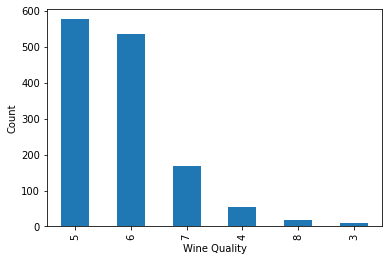

In [14]:
## Visualization to see if the data is imbalance or not
df1.quality.value_counts().plot(kind='bar')
plt.xlabel("Wine Quality")
plt.ylabel("Count")
plt.show()
#conclusion- It is an imbalanced dataset

In [15]:
# group count
print(df1["quality"].value_counts().sort_index())

df1["quality_group"] = np.where(df1["quality"] <= 4, "poor",
                      np.where(df1["quality"] <= 6, "average", "good"))

print(df1["quality_group"].value_counts(normalize=True) * 100)

3     10
4     53
5    577
6    535
7    167
8     17
Name: quality, dtype: int64
average    81.824871
good       13.539367
poor        4.635762
Name: quality_group, dtype: float64


In [16]:
df1.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_group
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,average
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,average
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,average
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,average
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,average


In [17]:
#Compare groups 
# Average of key features by quality score, with group sizes
print(df1.groupby("quality")[["alcohol", "volatile acidity", "sulphates", "citric acid"]]
         .agg(["count", "mean"]).round(2))

# Alcohol groups
df1["alcohol_group"] = np.where(df1["alcohol"] <= 10, "low",
                       np.where(df1["alcohol"] <= 11.5, "medium", "high"))

print(df1.groupby("alcohol_group")["quality"].mean().round(2)
         .reindex(["low", "medium", "high"]))

        alcohol        volatile acidity       sulphates       citric acid  \
          count   mean            count  mean     count  mean       count   
quality                                                                     
3            10   9.96               10  0.88        10  0.57          10   
4            53  10.27               53  0.69        53  0.60          53   
5           577   9.89              577  0.58       577  0.62         577   
6           535  10.66              535  0.50       535  0.67         535   
7           167  11.49              167  0.40       167  0.74         167   
8            17  12.16               17  0.43        17  0.77          17   

               
         mean  
quality        
3        0.17  
4        0.17  
5        0.24  
6        0.28  
7        0.37  
8        0.38  
alcohol_group
low       5.27
medium    5.73
high      6.38
Name: quality, dtype: float64


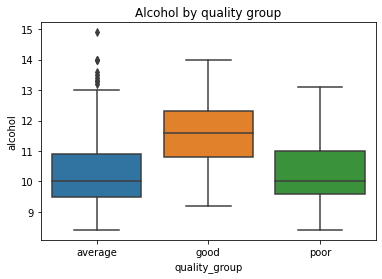

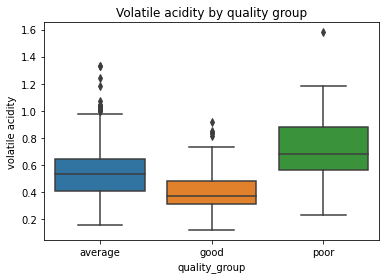

In [18]:
sns.boxplot(x="quality_group", y="alcohol", data=df1)
plt.title("Alcohol by quality group")
plt.show()

sns.boxplot(x="quality_group", y="volatile acidity", data=df1)
plt.title("Volatile acidity by quality group")
plt.show()

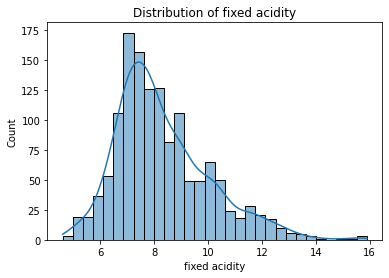

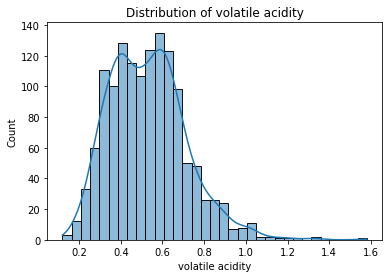

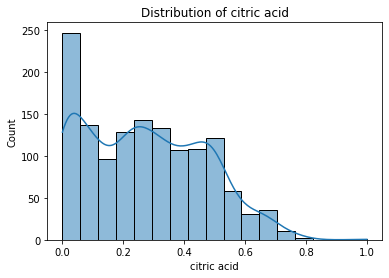

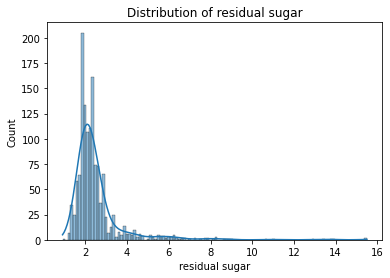

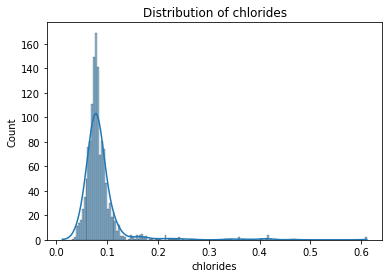

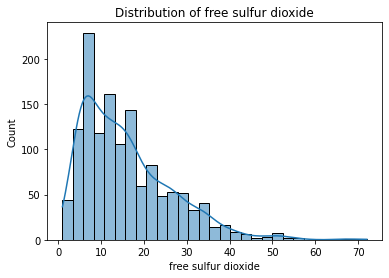

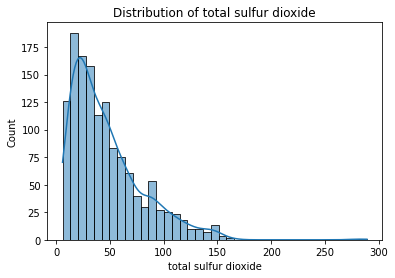

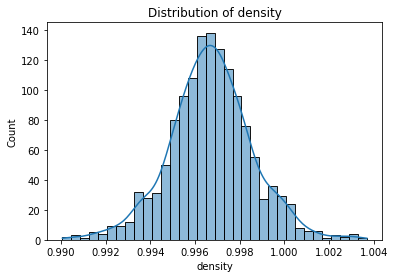

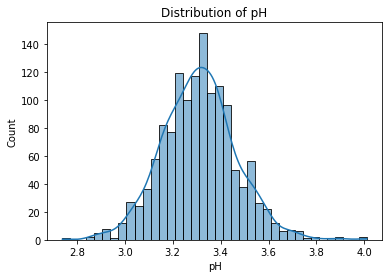

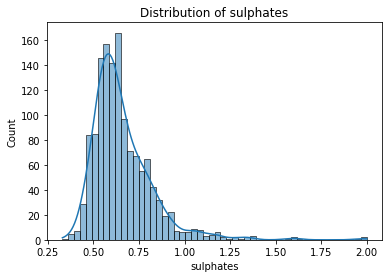

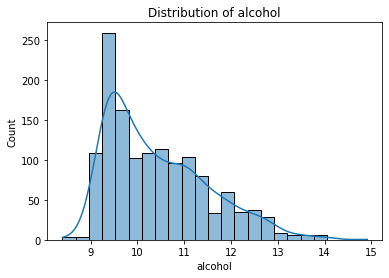

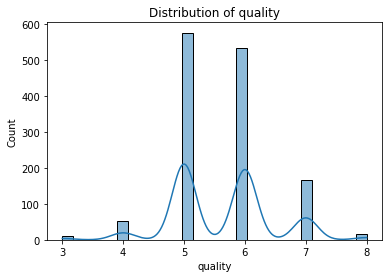

In [19]:
#Histplot
for column in df1.select_dtypes(include="number").columns:
    sns.histplot(df1[column], kde=True)
    plt.title(f"Distribution of {column}")
    plt.show()

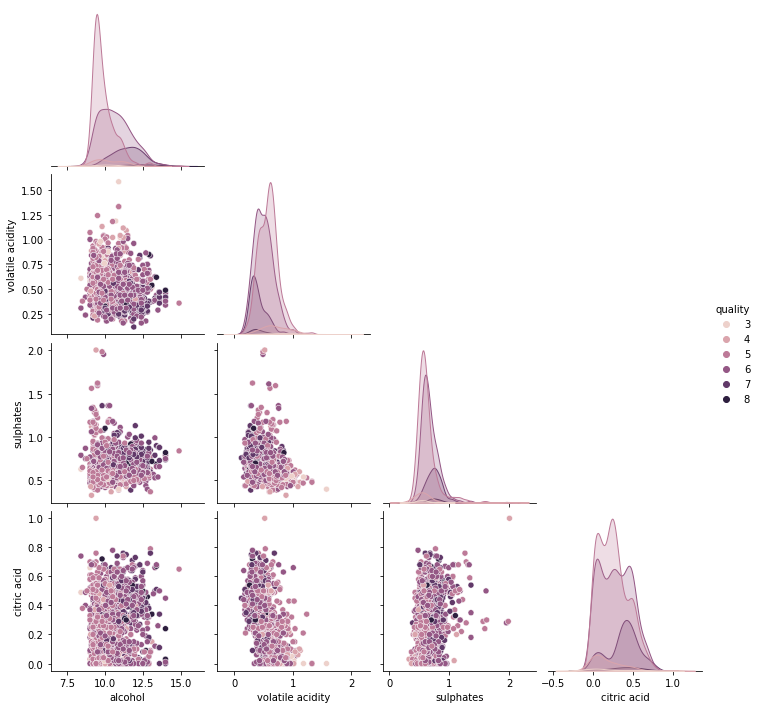

In [20]:
#univariate,bivariate,multivariate analysis
cols = ["alcohol", "volatile acidity", "sulphates", "citric acid", "quality"]
sns.pairplot(df1[cols], hue="quality", corner=True)
plt.show()

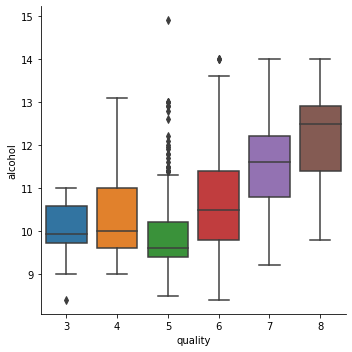

In [21]:
##categorical Plot
sns.catplot(x='quality', y='alcohol', data=df1, kind="box")
plt.show()

<AxesSubplot:xlabel='alcohol', ylabel='pH'>

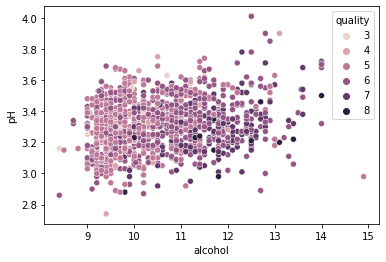

In [22]:
# Scatterplot 
sns.scatterplot(x='alcohol',y='pH',hue='quality',data=df1)

In [23]:
## Key findings

1. **Data quality:** No missing values. Removed 240 duplicate rows, leaving 1,359 wines.
2. **Imbalance:** About 82% of wines are "average" (quality 5 to 6), 13.5% are "good"
   (7 and above) and only 4.6% are "poor" (4 and below). Only 10 wines scored 3 and 17 scored 8,
   so conclusions about the extremes rest on small samples.
3. **Alcohol** has the strongest positive correlation with quality (r = 0.48).
   Average alcohol rises from about 9.9% for quality 5 wines to about 11.5% for quality 7 wines.
4. **Volatile acidity** has the strongest negative correlation (r = -0.40).
   Its average falls steadily from 0.88 (quality 3) to 0.40 (quality 7), so wines with
   more volatile acidity tend to score lower.
5. **Sulphates (r = 0.25) and citric acid (r = 0.23)** show weaker positive relationships.
6. **Residual sugar and free sulfur dioxide** show almost no relationship with quality.

## Limitations
- Correlation does not prove causation.
- Quality is a subjective taster score, not a measured property.
- Correlations are modest (none above 0.5), so no single feature predicts quality well.

## Next steps
Check skew and outliers in residual sugar and chlorides, and consider building a simple
model to predict quality.

SyntaxError: invalid syntax (2139212216.py, line 3)